<a href="https://colab.research.google.com/github/ManaswiKakad/Customer-Churn-Prediction-ML/blob/main/Orange_Telco_project_ipyn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Train shape: (2666, 20)
Test shape : (667, 20)
  State  Account length  Area code International plan Voice mail plan  \
0    KS             128        415                 No             Yes   
1    OH             107        415                 No             Yes   
2    NJ             137        415                 No              No   
3    OH              84        408                Yes              No   
4    OK              75        415                Yes              No   

   Number vmail messages  Total day minutes  Total day calls  \
0                     25              265.1              110   
1                     26              161.6              123   
2                      0              243.4              114   
3                      0              299.4               71   
4                      0              166.7              113   

   Total day charge  Total eve minutes  Total eve calls  Total eve charge  \
0             45.07              197.4              

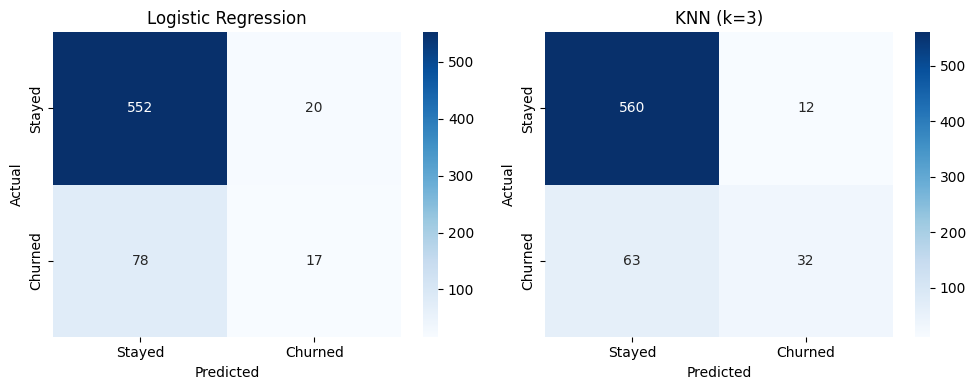

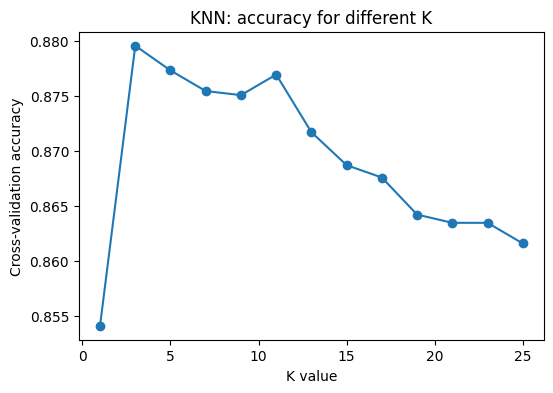

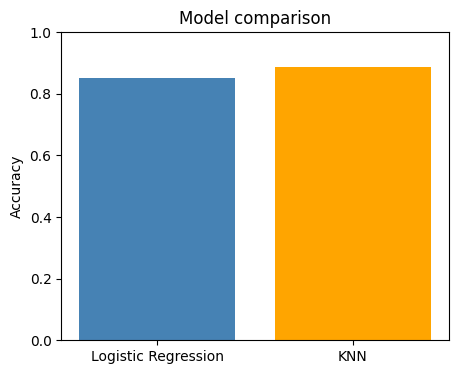

In [10]:
# Customer Churn Prediction - Orange Telecom dataset
# Models: Logistic Regression and K-Nearest Neighbors

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)




# ---------------------------------------------------------------
# 1. Load data
# ---------------------------------------------------------------
# In Colab: upload both files, or change the path to your Drive path
train = pd.read_csv("churn-bigml-80.csv")
test = pd.read_csv("churn-bigml-20.csv")

print("Train shape:", train.shape)
print("Test shape :", test.shape)
print(train.head())
print("\nMissing values in train:", train.isnull().sum().sum())
print("\nChurn counts:\n", train["Churn"].value_counts())

# ---------------------------------------------------------------
# 2. Preprocessing
# ---------------------------------------------------------------
def preprocess(df):
    df = df.copy()

    # Yes/No columns -> 1/0
    df["International plan"] = df["International plan"].map({"Yes": 1, "No": 0})
    df["Voice mail plan"] = df["Voice mail plan"].map({"Yes": 1, "No": 0})

    # Target column -> 1/0 (works whether it is True/False text or bool)
    df["Churn"] = df["Churn"].astype(str).str.lower().map({"true": 1, "false": 0})

    # State has 51 values, so one-hot would add many columns. Drop it.
    df = df.drop(columns=["State"])

    # Area code is just a label (408/415/510), so one-hot encode it
    df = pd.get_dummies(df, columns=["Area code"], dtype=int)
    return df

train = preprocess(train)
test = preprocess(test)

# Make sure both sets have exactly the same columns
test = test.reindex(columns=train.columns, fill_value=0)

X_train = train.drop(columns="Churn")
y_train = train["Churn"]
X_test = test.drop(columns="Churn")
y_test = test["Churn"]

# ---------------------------------------------------------------
# 3. Feature scaling (important for KNN and Logistic Regression)
# ---------------------------------------------------------------
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn from train only
X_test_s = scaler.transform(X_test)

# ---------------------------------------------------------------
# 4. Train models
# ---------------------------------------------------------------
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_s, y_train)

# Find a good K for KNN using 5-fold cross-validation on the TRAIN data only
# (so we never peek at the test set while tuning)
best_k, best_acc = 1, 0
k_values, k_scores = [], []
for k in range(1, 26, 2):
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    acc = cross_val_score(knn_temp, X_train_s, y_train, cv=5, scoring="accuracy").mean()
    k_values.append(k)
    k_scores.append(acc)
    if acc > best_acc:
        best_k, best_acc = k, acc
print("\nBest K for KNN:", best_k)

knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_s, y_train)

# ---------------------------------------------------------------
# 5. Evaluate
# ---------------------------------------------------------------
def evaluate(name, model):
    pred = model.predict(X_test_s)
    print(f"\n===== {name} =====")
    print("Accuracy :", round(accuracy_score(y_test, pred), 4))
    print("Precision:", round(precision_score(y_test, pred), 4))
    print("Recall   :", round(recall_score(y_test, pred), 4))
    print("F1 score :", round(f1_score(y_test, pred), 4))
    print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))
    return pred, accuracy_score(y_test, pred)

lr_pred, lr_acc = evaluate("Logistic Regression", lr)
knn_pred, knn_acc = evaluate(f"KNN (k={best_k})", knn)

# ---------------------------------------------------------------
# 6. Plots
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in zip(axes, [lr_pred, knn_pred],
                           ["Logistic Regression", f"KNN (k={best_k})"]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d",
                cmap="Blues", ax=ax,
                xticklabels=["Stayed", "Churned"],
                yticklabels=["Stayed", "Churned"])
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrices.png")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(k_values, k_scores, marker="o")
plt.xlabel("K value")
plt.ylabel("Cross-validation accuracy")
plt.title("KNN: accuracy for different K")
plt.savefig("knn_k_values.png")
plt.show()

plt.figure(figsize=(5, 4))
plt.bar(["Logistic Regression", "KNN"], [lr_acc, knn_acc], color=["steelblue", "orange"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Model comparison")
plt.savefig("model_comparison.png")
plt.show()

In [11]:
# Test 5 customers
sample = X_test_s[:5]

lr_pred = lr.predict(sample)
knn_pred = knn.predict(sample)

print("Actual:", y_test.iloc[:5].values)
print("Logistic Regression:", lr_pred)
print("KNN:", knn_pred)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, lr.predict(X_test_s)) * 100, 2), "%")

print("KNN Accuracy:",
      round(accuracy_score(y_test, knn.predict(X_test_s)) * 100, 2), "%")

Actual: [0 1 1 0 0]
Logistic Regression: [0 0 1 0 0]
KNN: [0 0 1 0 0]
Logistic Regression Accuracy: 85.31 %
KNN Accuracy: 88.76 %
